# Audio Preprocessing and Acoustic Feature Extraction

This notebook transforms multilingual audiobook MP3 clips into fixed-length feature vectors for spoken-language identification. It scans the corpus, checks MP3 metadata, filters duration outliers, preprocesses waveforms and extracts acoustic descriptors. German, Italian, Korean and Spanish are the four language labels. See [methodology](../docs/methodology.md) and [dataset instructions](../datasets/README.md).

## Configuration and dependencies

Input audio is organized by language and Male/Female subfolder. Paths are relative to the `notebooks/` working directory. The 60-second target is used for duration filtering, not for padding or cropping.

In [ ]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import librosa
import soundfile as sf

from mutagen.mp3 import MP3  # Used to get MP3 duration without full decoding

# Dataset root directory
DATASET_DIR = Path("../datasets/Dataset")

# Output directory for cleaned/preprocessed audio
OUTPUT_DIR = Path("../datasets/ProcessedDataset")

# Manifest files
MANIFEST_CSV = Path("../datasets/metadata_manifest.csv")
CLEAN_MANIFEST_CSV = Path("../datasets/metadata_clean_manifest.csv")

# Standard preprocessing settings
TARGET_SR = 16000
TARGET_DURATION_SEC = 60   # Fixed clip length
TOP_DB = 25                # Silence trimming sensitivity (lower => more trimming)

## Corpus inventory

Scan MP3 filenames, language and gender labels, and file sizes into a metadata manifest. The saved output lists 720 clips. Gender and paths are metadata, not model features.

In [ ]:
def scan_dataset(root: Path) -> pd.DataFrame:
    """
    Scan dataset folders and return a DataFrame with:
    language, gender, filepath, filename, size_bytes
    """
    rows = []
    if not root.exists():
        raise FileNotFoundError(f"Dataset folder not found: {root.resolve()}")

    # Each language folder is expected at root level
    languages = [p for p in root.iterdir() if p.is_dir()]

    for lang_dir in sorted(languages):
        language = lang_dir.name

        # Each language folder is expected to have Male and Female subfolders
        for gender in ["Male", "Female"]:
            gender_dir = lang_dir / gender
            if not gender_dir.exists():
                print(f"WARNING: Missing folder: {gender_dir}")
                continue

            mp3_files = sorted(gender_dir.glob("*.mp3"))
            for f in mp3_files:
                rows.append({
                    "language": language,
                    "gender": gender,
                    "filepath": str(f.as_posix()),
                    "filename": f.name,
                    "size_bytes": f.stat().st_size
                })

    return pd.DataFrame(rows)

df = scan_dataset(DATASET_DIR)
print("Total files found:", len(df))
df.head()

Total files found: 720


,language,gender,filepath,filename,size_bytes
0,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice02.mp3,1767130
1,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice07.mp3,1915924
2,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice08.mp3,2241932
3,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice09.mp3,2033788
4,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice12.mp3,2003695


## MP3 duration and metadata checks

Mutagen reads duration without fully decoding the waveform. A successful metadata read does not by itself guarantee successful audio decoding.

In [ ]:
def get_mp3_duration_sec(filepath: str):
    """
    Return (duration_seconds, error_message).
    If reading fails, duration is NaN and error_message is a string.
    """
    try:
        audio = MP3(filepath)
        return float(audio.info.length), None
    except Exception as e:
        return np.nan, str(e)

durations = []
errors = []

for fp in tqdm(df["filepath"].tolist(), desc="Reading MP3 duration"):
    d, err = get_mp3_duration_sec(fp)
    durations.append(d)
    errors.append(err)

df["duration_sec"] = durations
df["read_error"] = errors

# Save the initial manifest
df.to_csv(MANIFEST_CSV, index=False)
print("Saved:", MANIFEST_CSV.resolve())

df.head()

Reading MP3 duration: 100%|██████████| 720/720 [00:00<00:00, 1957.63it/s]

Saved: C:\Users\Farzam\MLProject\metadata_manifest.csv


,language,gender,filepath,filename,size_bytes,duration_sec,read_error
0,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice02.mp3,1767130,55.15,None
1,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice07.mp3,1915924,59.80,None
2,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice08.mp3,2241932,70.00,None
3,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice09.mp3,2033788,63.50,None
4,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice12.mp3,2003695,62.54,None


## Duration distribution and data quality

The recorded metadata check found no unreadable MP3 headers. The median duration is 60.687 s, but the maximum is 1534.24 s, motivating a duration filter.

Corrupted/unreadable files: 0


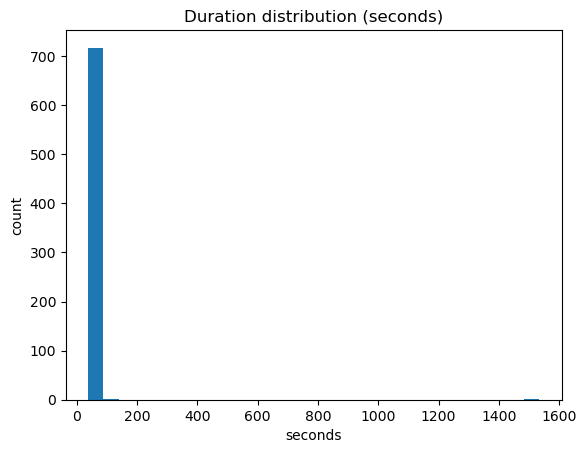

count     720.000000
mean       63.203247
std        55.215747
min        39.008750
25%        58.044082
50%        60.687236
75%        63.920255
max      1534.240000
Name: duration_sec, dtype: float64

In [ ]:
bad = df[df["read_error"].notna()]
print("Corrupted/unreadable files:", len(bad))
bad[["language", "gender", "filename", "read_error"]].head(10)
clean_candidates = df[df["read_error"].isna()].copy()

plt.figure()
plt.hist(clean_candidates["duration_sec"].dropna(), bins=30)
plt.title("Duration distribution (seconds)")
plt.xlabel("seconds")
plt.ylabel("count")
plt.show()

clean_candidates["duration_sec"].describe()

## Duration filtering

Keep clips with readable metadata and original durations in the inclusive interval [50, 70] seconds. The saved results retain 655 of 720 clips and exclude 65 duration outliers.

In [ ]:
Threshold = 10
MIN_SEC = TARGET_DURATION_SEC - Threshold
MAX_SEC = TARGET_DURATION_SEC + Threshold

df_clean = df[
    (df["read_error"].isna()) &
    (df["duration_sec"].between(MIN_SEC, MAX_SEC))
].copy()

df_outliers = df[
    (df["read_error"].isna()) &
    (~df["duration_sec"].between(MIN_SEC, MAX_SEC))
].copy()

print("Kept (clean):", len(df_clean))
print("Outliers (duration):", len(df_outliers))

df_outliers[["language", "gender", "filename", "duration_sec"]].head(10)

Kept (clean): 655
Outliers (duration): 65


,language,gender,filename,duration_sec
9,German,Male,810100162_male_german_voice04.mp3,49.032000
11,German,Male,810100162_male_german_voice06.mp3,81.024000
12,German,Male,810100162_male_german_voice07.mp3,73.032000
14,German,Male,810100162_male_german_voice12.mp3,82.032000
17,German,Male,810101399_male_german_voice01.mp3,97.785442
18,German,Male,810101399_male_german_voice02.mp3,71.019909
21,German,Male,810101399_male_german_voice11.mp3,72.692744
22,German,Male,810101399_male_german_voice14.mp3,77.407143
36,German,Male,810101477_male_german_voice13.mp3,46.080000
44,German,Male,810101607_male_german_voice13.mp3,80.828209


## Waveform preprocessing

Load mono audio at 16 kHz, trim leading/trailing low-energy regions (`top_db=25`), peak-normalize nonzero signals, and write 16-bit PCM WAV. This standardizes sample rate and amplitude but does not perform explicit denoising, augmentation or fixed-length cropping. Existing WAV files are reused; remove the processed directory before a clean regeneration if preprocessing settings change.

In [ ]:
def preprocess_audio(filepath: str, target_sr=16000, top_db=25):
    """
    Load an MP3 file, standardize it, and return (audio_array, sample_rate).
    Steps:
      - Load as mono and resample
      - Trim leading/trailing silence
      - Peak normalize
    """
    # Load MP3 -> mono + resample to target_sr
    y, sr = librosa.load(filepath, sr=target_sr, mono=True)

    # Trim silence
    y, _ = librosa.effects.trim(y, top_db=top_db)

    # Peak normalization
    peak = np.max(np.abs(y)) if len(y) else 0.0
    if peak > 0:
        y = y / peak

    return y, sr  # Return actual sr


def output_path_for_row(row, output_root: Path) -> Path:
    """
    Build output path:
    ProcessedDataset/Language/Gender/<filename>.wav
    """
    out_dir = output_root / row["language"] / row["gender"]
    out_dir.mkdir(parents=True, exist_ok=True)
    out_name = Path(row["filename"]).with_suffix(".wav").name
    return out_dir / out_name


processed_rows = []
failed_rows = []

for _, row in tqdm(df_clean.iterrows(), total=len(df_clean), desc="Preprocessing"):
    in_fp = row["filepath"]
    out_fp = output_path_for_row(row, OUTPUT_DIR)

    # Skip if already processed (useful for resuming)
    if out_fp.exists():
        processed_rows.append({**row, "processed_path": str(out_fp.as_posix()), "process_error": None})
        continue

    try:
        y, sr = preprocess_audio(
            in_fp,
            target_sr=TARGET_SR,
            top_db=TOP_DB
        )
        # Save as 16-bit PCM WAV
        sf.write(out_fp, y, sr, subtype="PCM_16")
        processed_rows.append({**row, "processed_path": str(out_fp.as_posix()), "process_error": None})
    except Exception as e:
        failed_rows.append({**row, "processed_path": None, "process_error": str(e)})

df_processed = pd.DataFrame(processed_rows)
df_failed = pd.DataFrame(failed_rows)

# Save clean manifest
df_processed.to_csv(CLEAN_MANIFEST_CSV, index=False)

print("Saved clean manifest:", CLEAN_MANIFEST_CSV.resolve())
print("Processed OK:", len(df_processed))
print("Failed during processing:", len(df_failed))

df_failed.head()

Preprocessing:  49%|████▉     | 321/655 [00:00<00:00, 3201.19it/s]C:\Users\Farzam\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\Users\Farzam\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\Users\Farzam\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,
Preprocessing: 100%|██████████| 655/655 [00:49<00:00, 13.10it/s]  

Saved clean manifest: C:\Users\Farzam\MLProject\metadata_clean_manifest.csv
Processed OK: 655
Failed during processing: 0


""


## Acoustic feature extraction

Generate a 128-dimensional vector per clip using mean and standard deviation of frame-wise time-domain, spectral and time-frequency descriptors. This fixed-size representation permits classical machine learning on variable-duration recordings.

### Feature configuration

Use 13 MFCCs, a 2048-sample FFT and a hop of 512 samples at 16 kHz. The FFT window spans 128 ms and the hop 32 ms; the library defaults are retained for other settings.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
from tqdm import tqdm

import librosa

# Paths
CLEAN_MANIFEST_CSV = Path("../datasets/metadata_clean_manifest.csv")
FEATURES_CSV = Path("../datasets/features_table.csv")

# Audio / feature settings
TARGET_SR = 16000
N_MFCC = 13
HOP_LENGTH = 512
N_FFT = 2048

### Read the processed manifest

Validate the required metadata columns before accessing processed WAV files. The recorded manifest has 655 rows.

In [ ]:
if not CLEAN_MANIFEST_CSV.exists():
    raise FileNotFoundError(
        "metadata_clean_manifest.csv not found. "
        "Make sure you finished the cleaning step and saved CLEAN_MANIFEST_CSV."
    )

df_proc = pd.read_csv(CLEAN_MANIFEST_CSV)

required_cols = {"language", "gender", "processed_path"}
missing = required_cols - set(df_proc.columns)
if missing:
    raise ValueError(f"Missing columns in manifest: {missing}")

print("Rows in manifest:", len(df_proc))
df_proc.head()

Rows in manifest: 655


,language,gender,filepath,filename,size_bytes,duration_sec,read_error,processed_path,process_error
0,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice02.mp3,1767130,55.15,NaN,ProcessedDataset/German/Male/810100147_male_ge...,NaN
1,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice07.mp3,1915924,59.80,NaN,ProcessedDataset/German/Male/810100147_male_ge...,NaN
2,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice08.mp3,2241932,70.00,NaN,ProcessedDataset/German/Male/810100147_male_ge...,NaN
3,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice09.mp3,2033788,63.50,NaN,ProcessedDataset/German/Male/810100147_male_ge...,NaN
4,German,Male,Dataset/German/Male/810100147_male_german_voic...,810100147_male_german_voice12.mp3,2003695,62.54,NaN,ProcessedDataset/German/Male/810100147_male_ge...,NaN


### Frame-wise descriptors and statistical pooling

Time-domain descriptors: zero-crossing rate and RMS. Spectral descriptors: centroid, bandwidth, 85% rolloff, flatness and seven contrast bands. Time-frequency descriptors: 13 MFCCs, 13 first-order and 13 second-order MFCC deltas, and 12 chroma coefficients. Pool each descriptor using its temporal mean and standard deviation: 2 × (2 + 4 + 7 + 39 + 12) = 128 features. Pooling preserves overall statistics but discards most temporal ordering.

In [ ]:
def summarize_feature(mat: np.ndarray, prefix: str) -> dict:
    """
    Summarize a 2D feature matrix of shape (n_features, n_frames)
    into fixed-length statistics (mean, std) for each feature row.
    """
    out = {}
    if mat.ndim == 1:
        mat = mat.reshape(1, -1)

    means = np.mean(mat, axis=1)
    stds = np.std(mat, axis=1)

    for i, (m, s) in enumerate(zip(means, stds)):
        out[f"{prefix}_{i}_mean"] = float(m)
        out[f"{prefix}_{i}_std"] = float(s)
    return out


def extract_features(filepath: str, target_sr=16000) -> dict:
    """
    Extract a fixed-length feature vector from an audio file.
    Feature groups:
      - Time-domain: ZCR, RMS
      - Frequency-domain: centroid, bandwidth, rolloff, flatness, contrast
      - Time-frequency: MFCC, delta, delta2, chroma
    """
    y, sr = librosa.load(filepath, sr=target_sr, mono=True)

    feats = {}

    # Time-domain features
    zcr = librosa.feature.zero_crossing_rate(y, hop_length=HOP_LENGTH)
    rms = librosa.feature.rms(y=y, hop_length=HOP_LENGTH)

    feats.update(summarize_feature(zcr, "zcr"))
    feats.update(summarize_feature(rms, "rms"))

    # Frequency-domain features
    centroid = librosa.feature.spectral_centroid(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)
    bandwidth = librosa.feature.spectral_bandwidth(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)
    rolloff = librosa.feature.spectral_rolloff(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH, roll_percent=0.85)
    flatness = librosa.feature.spectral_flatness(y=y, n_fft=N_FFT, hop_length=HOP_LENGTH)
    contrast = librosa.feature.spectral_contrast(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)

    feats.update(summarize_feature(centroid, "spec_centroid"))
    feats.update(summarize_feature(bandwidth, "spec_bandwidth"))
    feats.update(summarize_feature(rolloff, "spec_rolloff"))
    feats.update(summarize_feature(flatness, "spec_flatness"))
    feats.update(summarize_feature(contrast, "spec_contrast"))

    # Time-frequency features
    mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, n_fft=N_FFT, hop_length=HOP_LENGTH)
    mfcc_delta = librosa.feature.delta(mfcc)
    mfcc_delta2 = librosa.feature.delta(mfcc, order=2)

    chroma = librosa.feature.chroma_stft(y=y, sr=sr, n_fft=N_FFT, hop_length=HOP_LENGTH)

    feats.update(summarize_feature(mfcc, "mfcc"))
    feats.update(summarize_feature(mfcc_delta, "mfcc_delta"))
    feats.update(summarize_feature(mfcc_delta2, "mfcc_delta2"))
    feats.update(summarize_feature(chroma, "chroma"))

    return feats

### Single-file feature sanity check

The example confirms a 128-feature vector. The saved dependency warnings are retained as part of the original output.

In [ ]:
test_path = df_proc.loc[0, "processed_path"]
test_feats = extract_features(test_path, target_sr=TARGET_SR)

print("Test file:", test_path)
print("Number of extracted features:", len(test_feats))
list(test_feats.items())[:10]

C:\Users\Farzam\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\Users\Farzam\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\Users\Farzam\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


Test file: ProcessedDataset/German/Male/810100147_male_german_voice02.wav
Number of extracted features: 128


[('zcr_0_mean', 0.14304329234467456),
 ('zcr_0_std', 0.10412219886622882),
 ('rms_0_mean', 0.060331184417009354),
 ('rms_0_std', 0.050995420664548874),
 ('spec_centroid_0_mean', 1944.5245753206432),
 ('spec_centroid_0_std', 919.4636435335565),
 ('spec_bandwidth_0_mean', 1754.4964119541012),
 ('spec_bandwidth_0_std', 383.4471552606985),
 ('spec_rolloff_0_mean', 3792.964127218935),
 ('spec_rolloff_0_std', 1497.7697582372364)]

### Batch extraction

Process all 655 retained WAV files. The recorded feature extraction completed with no failures.

In [ ]:
rows = []
failed = []

for _, row in tqdm(df_proc.iterrows(), total=len(df_proc), desc="Extracting features"):
    fp = row["processed_path"]
    try:
        feats = extract_features(fp, target_sr=TARGET_SR)
        rows.append({
            "language": row["language"],
            "gender": row["gender"],
            "processed_path": fp,
            **feats
        })
    except Exception as e:
        failed.append({"processed_path": fp, "error": str(e)})

df_features = pd.DataFrame(rows)

print("Extracted feature rows:", len(df_features))
print("Failed files:", len(failed))
df_features.head()

Extracting features: 100%|██████████| 655/655 [09:27<00:00,  1.15it/s]

Extracted feature rows: 655
Failed files: 0


,language,gender,processed_path,zcr_0_mean,zcr_0_std,rms_0_mean,rms_0_std,spec_centroid_0_mean,spec_centroid_0_std,spec_bandwidth_0_mean,...,chroma_7_mean,chroma_7_std,chroma_8_mean,chroma_8_std,chroma_9_mean,chroma_9_std,chroma_10_mean,chroma_10_std,chroma_11_mean,chroma_11_std
0,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.143043,0.104122,0.060331,0.050995,1944.524575,919.463644,1754.496412,...,0.382088,0.312580,0.421553,0.324034,0.427405,0.323133,0.444297,0.339997,0.432369,0.332017
1,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.127733,0.104457,0.056066,0.045961,1789.767551,960.672971,1720.709832,...,0.351764,0.295726,0.408453,0.304481,0.453395,0.308593,0.490467,0.338070,0.453111,0.328605
2,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.105597,0.085899,0.067285,0.058645,1552.156550,834.720557,1646.997488,...,0.409158,0.309259,0.470213,0.315853,0.499733,0.316083,0.514571,0.342777,0.437941,0.318487
3,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.106475,0.084021,0.058888,0.046811,1620.251206,839.514078,1688.599766,...,0.330343,0.290463,0.402950,0.318937,0.448556,0.315676,0.506503,0.328448,0.498888,0.340772
4,German,Male,ProcessedDataset/German/Male/810100147_male_ge...,0.114301,0.105571,0.050911,0.043566,1645.476240,971.215322,1680.336391,...,0.372121,0.307793,0.399794,0.305063,0.456234,0.318075,0.515569,0.352761,0.470837,0.327594


### Export feature table

The table contains 128 numeric features and three metadata columns (`language`, `gender`, `processed_path`). The classification and clustering notebooks read the same file.

In [ ]:
df_features.to_csv(FEATURES_CSV, index=False)
print("Saved:", FEATURES_CSV.resolve())

if len(failed) > 0:
    df_failed = pd.DataFrame(failed)
    df_failed.to_csv("../datasets/feature_extraction_failed.csv", index=False)
    print("Saved failures:", Path("../datasets/feature_extraction_failed.csv").resolve())

Saved: C:\Users\Farzam\MLProject\features_table.csv


## Summary

Of 720 scanned MP3 clips, 655 (90.97%) passed the duration filter. The recorded preprocessing and feature extraction stages report zero failures for those clips. Each clip is represented by 128 acoustic statistics. The resulting table is the shared input for both modeling notebooks. These preprocessing choices reduce some recording variability but cannot eliminate speaker, audiobook or recording-source effects.